# Breast Cancer Prediction System

## Machine Learning Project

**Dataset:** Wisconsin Breast Cancer Diagnostic Dataset

**Objective:** To develop a machine learning classification system
that predicts whether a tumor is benign or malignant based on
30 diagnostic measurements.

**Algorithms:**
1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Random Forest

In [1]:
# Import required libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer

# Display settings
pd.set_option('display.max_columns', None)

# Load the Wisconsin Breast Cancer Dataset
cancer = load_breast_cancer()

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [2]:
# Load the downloaded CSV dataset

df = pd.read_csv("/home/nayeem/breast-cancer-prediction/data/breast_cancer.csv")

# Display first 5 rows
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
# Display number of rows and columns

print("Dataset Shape:", df.shape)
print("Total Samples:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (569, 31)
Total Samples: 569
Total Columns: 31


In [4]:
# Display all column names

print(df.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']


In [5]:
# Display dataset information

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
# Display statistical summary of numerical columns

df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,0.405172,1.216853,2.866059,40.337079,0.007041,0.025478,0.031894,0.011796,0.020542,0.003795,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,0.277313,0.551648,2.021855,45.491006,0.003003,0.017908,0.030186,0.006170,0.008266,0.002646,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,0.111500,0.360200,0.757000,6.802000,0.001713,0.002252,0.000000,0.000000,0.007882,0.000895,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,0.232400,0.833900,1.606000,17.850000,0.005169,0.013080,0.015090,0.007638,0.015160,0.002248,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,0.324200,1.108000,2.287000,24.530000,0.006380,0.020450,0.025890,0.010930,0.018730,0.003187,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,0.478900,1.474000,3.357000,45.190000,0.008146,0.032450,0.042050,0.014710,0.023480,0.004558,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,2.873000,4.885000,21.980000,542.200000,0.031130,0.135400,0.396000,0.052790,0.078950,0.029840,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [7]:
# Check missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values in Each Column:
mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

Total Missing Values: 0


In [8]:
# Check duplicate rows

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [9]:
# Count samples in each target class

print("Target Class Distribution:")
print(df['target'].value_counts().sort_index())

Target Class Distribution:
target
0    212
1    357
Name: count, dtype: int64


In [10]:
# Display class names instead of numerical labels

class_counts = df['target'].map({
    0: 'Malignant',
    1: 'Benign'
}).value_counts()

print(class_counts)

target
Benign       357
Malignant    212
Name: count, dtype: int64


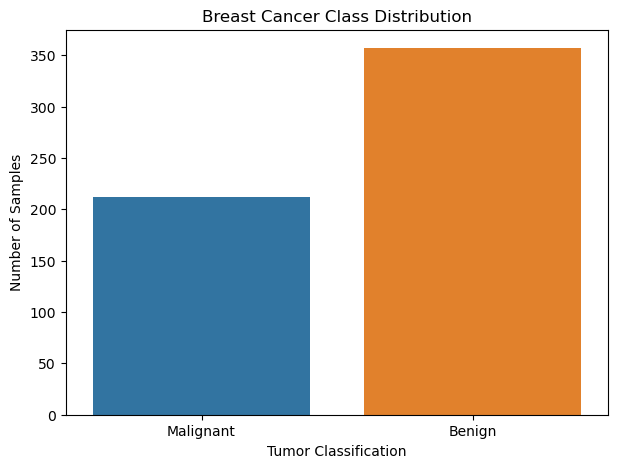

In [11]:
# Visualize target class distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='target',
    hue='target',
    legend=False
)

plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.title('Breast Cancer Class Distribution')
plt.xlabel('Tumor Classification')
plt.ylabel('Number of Samples')

plt.show()

In [12]:
# Verify CSV dataset against original Scikit-learn dataset

feature_match = (
    df.drop(columns=['target']).columns.tolist()
    == cancer.feature_names.tolist()
)

target_match = np.array_equal(
    df['target'].to_numpy(),
    cancer.target
)

data_match = np.allclose(
    df.drop(columns=['target']).to_numpy(),
    cancer.data
)

print("Feature Names Match:", feature_match)
print("Target Values Match:", target_match)
print("Feature Data Match:", data_match)

Feature Names Match: True
Target Values Match: True
Feature Data Match: True


In [13]:
# Calculate target class percentages

target_percentage = (
    df['target']
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Target Class Distribution (%):")

print(f"Malignant: {target_percentage[0]:.2f}%")
print(f"Benign: {target_percentage[1]:.2f}%")

Target Class Distribution (%):
Malignant: 37.26%
Benign: 62.74%


In [14]:
# Display statistical information about all features

df.describe().T

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


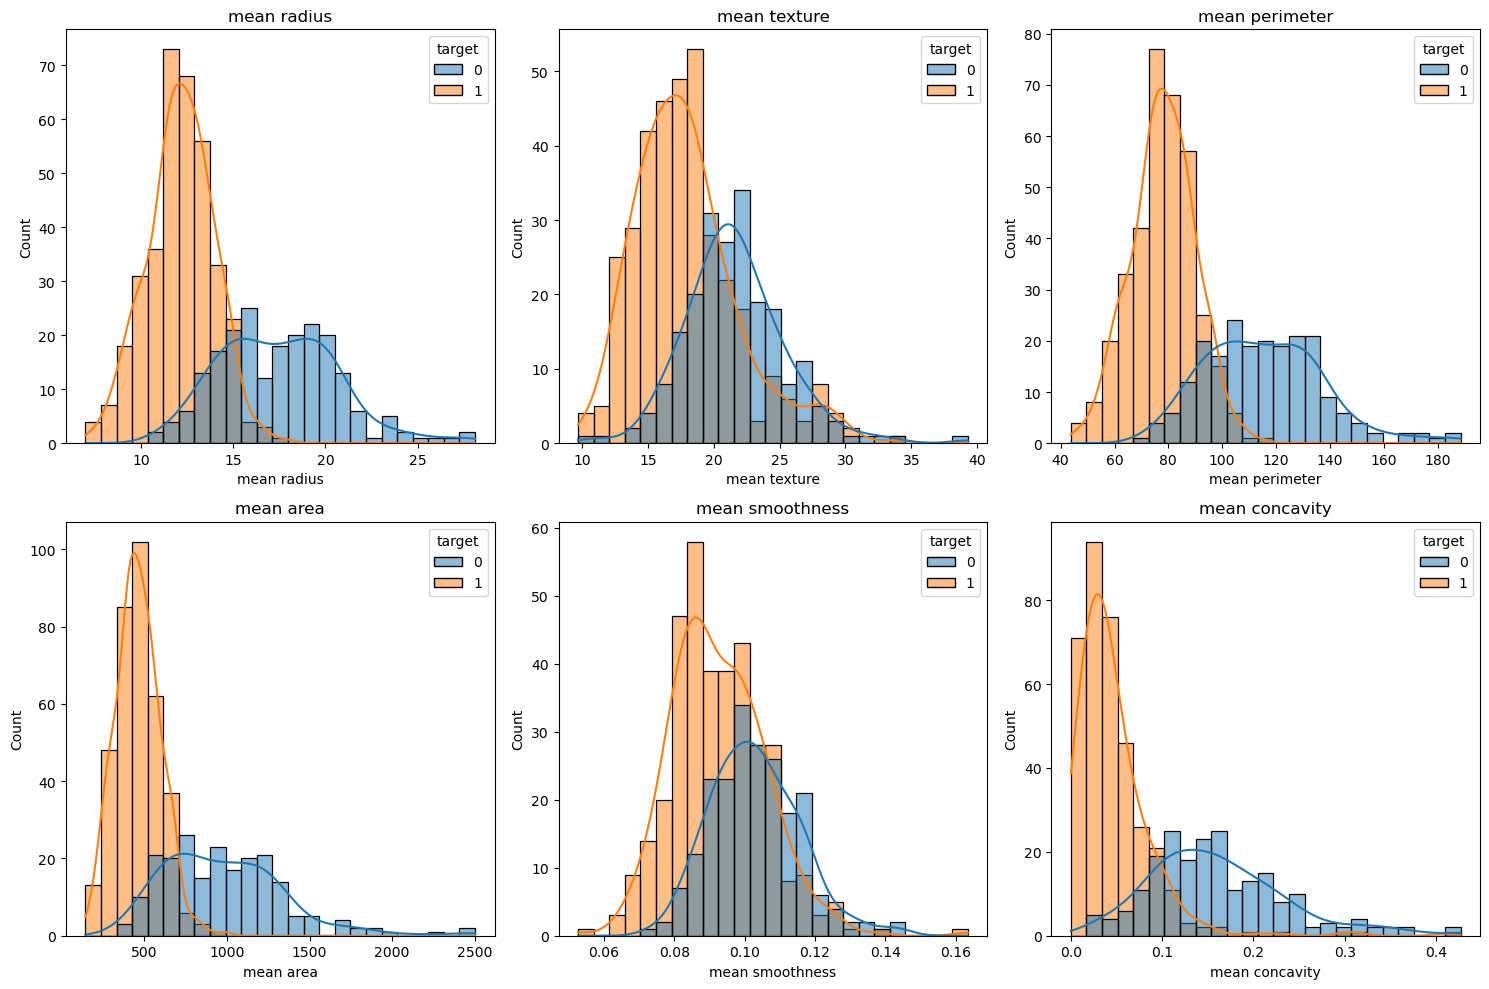

In [15]:
# Select important features for visualization

selected_features = [
    'mean radius',
    'mean texture',
    'mean perimeter',
    'mean area',
    'mean smoothness',
    'mean concavity'
]

# Create distribution plots

plt.figure(figsize=(15, 10))

for i, feature in enumerate(selected_features, 1):

    plt.subplot(2, 3, i)

    sns.histplot(
        data=df,
        x=feature,
        hue='target',
        kde=True,
        bins=25
    )

    plt.title(feature)

plt.tight_layout()
plt.show()

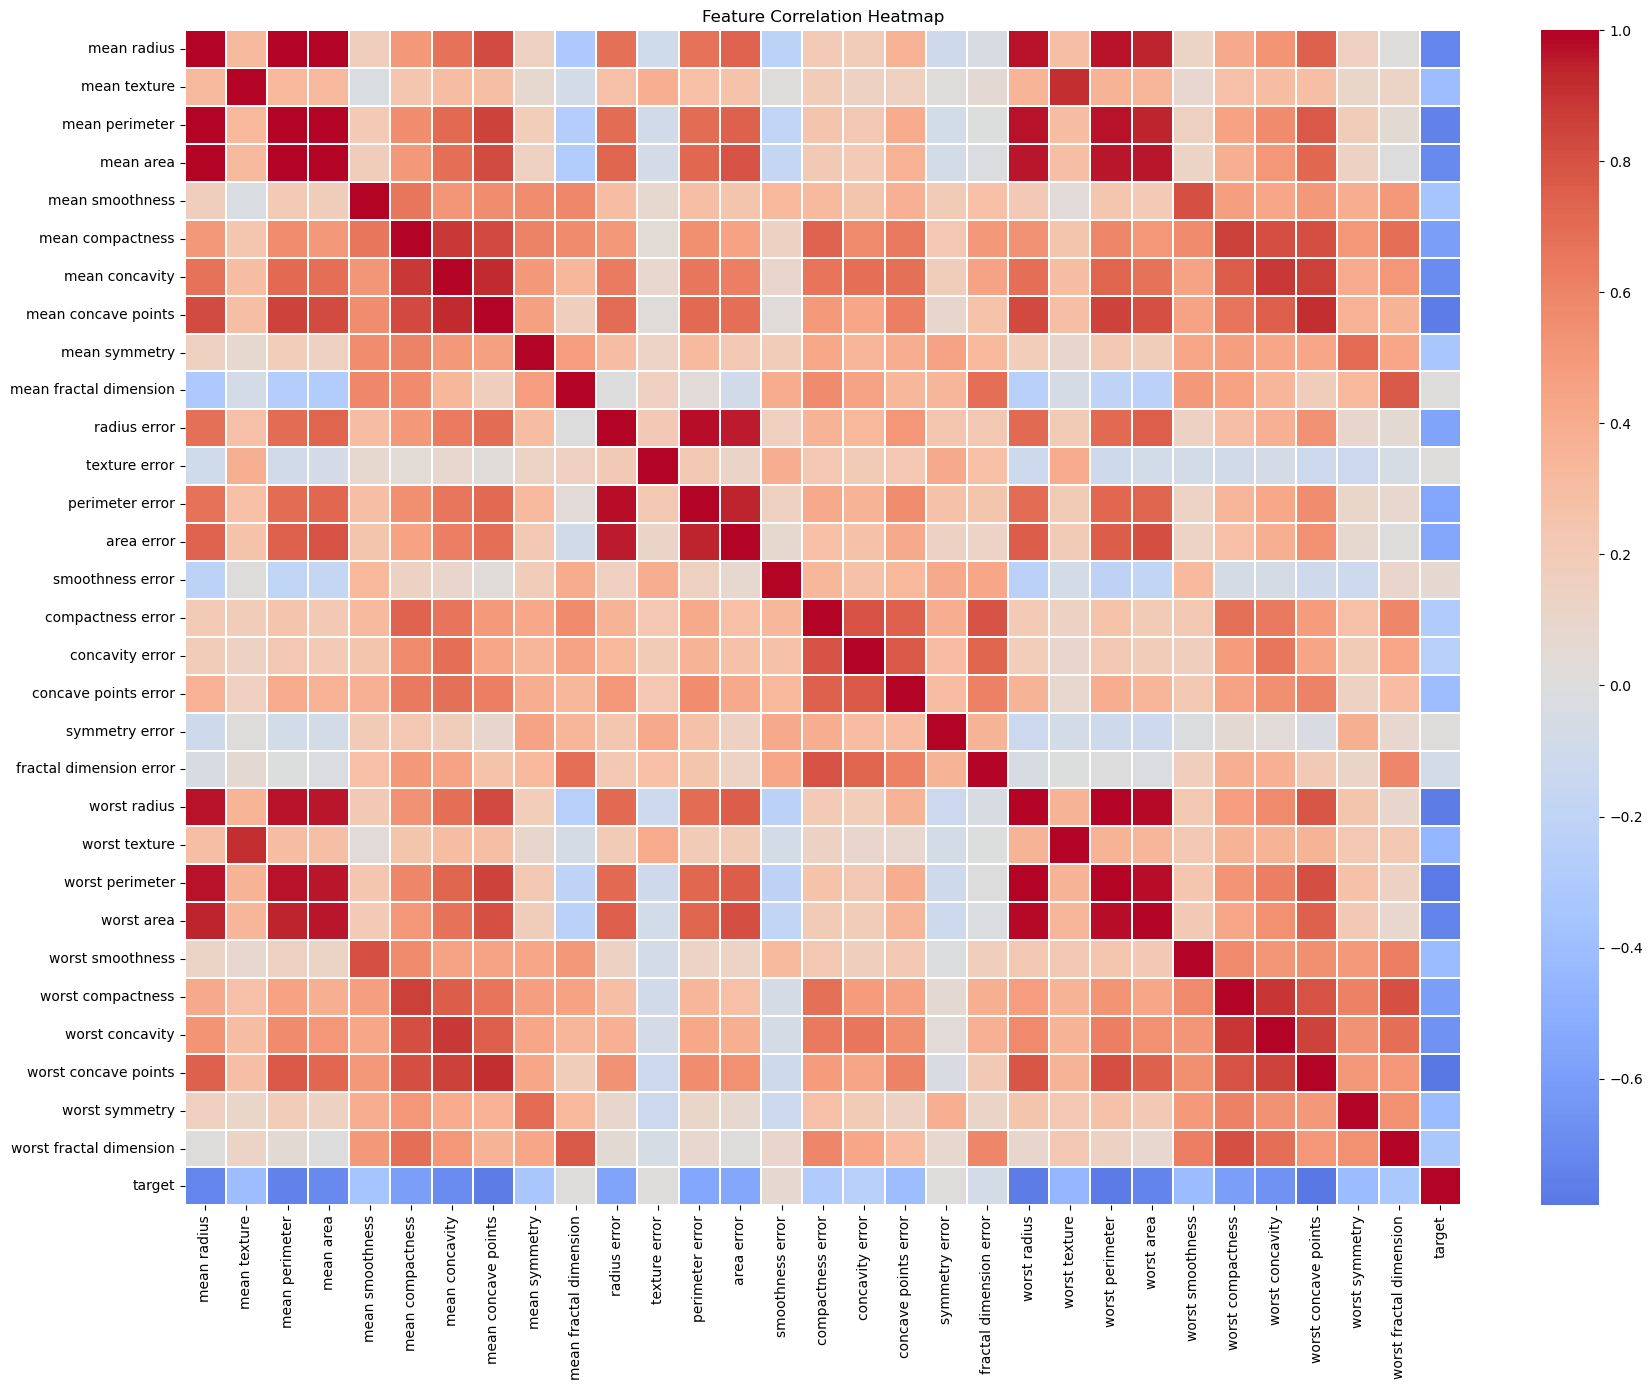

In [16]:
# Calculate correlation between numerical features

correlation_matrix = df.corr()

# Display correlation heatmap

plt.figure(figsize=(18, 14))

sns.heatmap(
    correlation_matrix,
    cmap='coolwarm',
    center=0,
    linewidths=0.1
)

plt.title('Feature Correlation Heatmap')

plt.tight_layout()
plt.show()

In [17]:
# Calculate correlation with target

target_correlation = (
    correlation_matrix['target']
    .drop('target')
    .sort_values(key=abs, ascending=False)
)

print("Top 10 Features Correlated with Target:")

display(target_correlation.head(10))

Top 10 Features Correlated with Target:


worst concave points   -0.793566
worst perimeter        -0.782914
mean concave points    -0.776614
worst radius           -0.776454
mean perimeter         -0.742636
worst area             -0.733825
mean radius            -0.730029
mean area              -0.708984
mean concavity         -0.696360
worst concavity        -0.659610
Name: target, dtype: float64

In [18]:
# Separate independent variables (X) and dependent variable (y)

X = df.drop('target', axis=1)

y = df['target']

# Display shapes

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [19]:
# Check target labels

print("Unique Target Values:", sorted(y.unique()))

print("\nTarget Mapping:")
print("0 = Malignant")
print("1 = Benign")

Unique Target Values: [np.int64(0), np.int64(1)]

Target Mapping:
0 = Malignant
1 = Benign


In [20]:
# Import train_test_split

from sklearn.model_selection import train_test_split

In [21]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset sizes

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [22]:
# Check class distribution in training and testing sets

print("Training Set Distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting Set Distribution:")
print(y_test.value_counts().sort_index())

Training Set Distribution:
target
0    170
1    285
Name: count, dtype: int64

Testing Set Distribution:
target
0    42
1    72
Name: count, dtype: int64


In [23]:
# Import tools for feature scaling and machine learning pipelines

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [24]:
# Create a pipeline for Logistic Regression
# StandardScaler scales the features before model training

from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=10000))
])

In [25]:
# Import KNN classifier
from sklearn.neighbors import KNeighborsClassifier

# Create a pipeline for KNN
# Scaling is important for distance-based algorithms like KNN

knn_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', KNeighborsClassifier(n_neighbors=5))
])

In [26]:
# Import Random Forest classifier
from sklearn.ensemble import RandomForestClassifier

# Create a pipeline for Random Forest
# Scaling is not required for Random Forest

rf_model = Pipeline([
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

In [27]:
# Train Logistic Regression model
logistic_model.fit(X_train, y_train)

# Train KNN model
knn_model.fit(X_train, y_train)

# Train Random Forest model
rf_model.fit(X_train, y_train)

print("All three models trained successfully!")

All three models trained successfully!


In [28]:
# Make predictions using the testing dataset

y_pred_logistic = logistic_model.predict(X_test)

y_pred_knn = knn_model.predict(X_test)

y_pred_rf = rf_model.predict(X_test)

print("Predictions completed successfully!")

Predictions completed successfully!


In [29]:
# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [30]:
# Calculate evaluation metrics for all three models

models = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf
}

for name, predictions in models.items():
    print(f"\n{name}")
    print("-------------------------")

    print("Accuracy:", accuracy_score(y_test, predictions))
    print("Precision:", precision_score(y_test, predictions))
    print("Recall:", recall_score(y_test, predictions))
    print("F1-Score:", f1_score(y_test, predictions))


Logistic Regression
-------------------------
Accuracy: 0.9824561403508771
Precision: 0.9861111111111112
Recall: 0.9861111111111112
F1-Score: 0.9861111111111112

KNN
-------------------------
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1-Score: 0.9655172413793104

Random Forest
-------------------------
Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1-Score: 0.9655172413793104


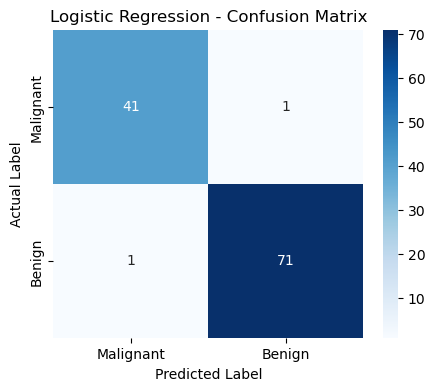

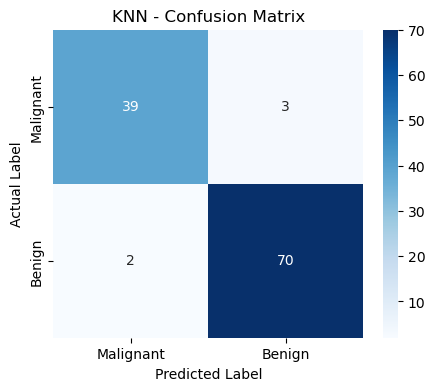

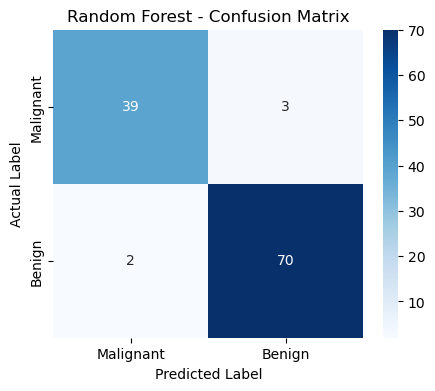

In [31]:
# Import visualization library
import matplotlib.pyplot as plt
import seaborn as sns

# Store model predictions
predictions = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf
}

# Plot confusion matrices
for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Malignant', 'Benign'],
        yticklabels=['Malignant', 'Benign']
    )

    plt.title(f'{name} - Confusion Matrix')
    plt.xlabel('Predicted Label')
    plt.ylabel('Actual Label')
    plt.show()

In [32]:
# Generate classification reports for all three models

predictions = {
    "Logistic Regression": y_pred_logistic,
    "KNN": y_pred_knn,
    "Random Forest": y_pred_rf
}

for name, y_pred in predictions.items():

    print(f"\n{name}")
    print("=" * 50)

    print(classification_report(
        y_test,
        y_pred,
        target_names=['Malignant', 'Benign']
    ))


Logistic Regression
              precision    recall  f1-score   support

   Malignant       0.98      0.98      0.98        42
      Benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


KNN
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Random Forest
              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96

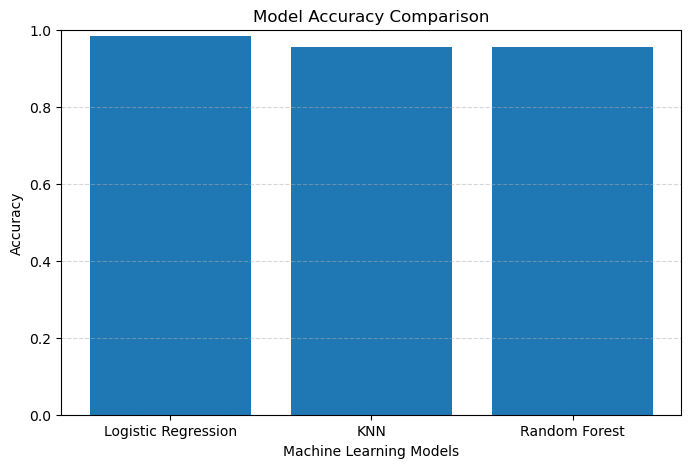

In [33]:
# Compare model performance using accuracy

model_names = [
    'Logistic Regression',
    'KNN',
    'Random Forest'
]

accuracies = [
    accuracy_score(y_test, y_pred_logistic),
    accuracy_score(y_test, y_pred_knn),
    accuracy_score(y_test, y_pred_rf)
]

plt.figure(figsize=(8, 5))

plt.bar(model_names, accuracies)

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Models')
plt.ylabel('Accuracy')

plt.ylim(0, 1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

In [34]:
# Display final model comparison

print("FINAL MODEL COMPARISON")
print("=" * 40)

print(f"Logistic Regression: {accuracies[0]*100:.2f}%")
print(f"KNN: {accuracies[1]*100:.2f}%")
print(f"Random Forest: {accuracies[2]*100:.2f}%")

best_model_index = accuracies.index(max(accuracies))

print("\nBest Performing Model:", model_names[best_model_index])

FINAL MODEL COMPARISON
Logistic Regression: 98.25%
KNN: 95.61%
Random Forest: 95.61%

Best Performing Model: Logistic Regression


### Conclusion

In this experiment, three machine learning algorithms—Logistic Regression, K-Nearest Neighbors (KNN), and Random Forest—were applied to the Breast Cancer Wisconsin dataset.

The models were evaluated using Accuracy, Precision, Recall, F1-Score, and Confusion Matrix.

Among the three models, Logistic Regression achieved the highest accuracy of **98.25%**, while KNN and Random Forest both achieved **95.61%** accuracy.

Therefore, Logistic Regression performed best on this test dataset.

In [35]:
for name, obj in list(globals().items()):
    if hasattr(obj, 'predict') and hasattr(obj, 'fit'):
        print(name, ":", type(obj).__name__)

Pipeline : ABCMeta
LogisticRegression : type
logistic_model : Pipeline
KNeighborsClassifier : ABCMeta
knn_model : Pipeline
RandomForestClassifier : ABCMeta
rf_model : Pipeline


In [36]:
import joblib
import os

# Create a folder to store trained models
os.makedirs("models", exist_ok=True)

# Save all three trained models
joblib.dump(logistic_model, "models/logistic_model.pkl")
joblib.dump(knn_model, "models/knn_model.pkl")
joblib.dump(rf_model, "models/random_forest_model.pkl")

print("All models saved successfully!")

All models saved successfully!


In [37]:
import joblib

# Load saved models
loaded_logistic = joblib.load("models/logistic_model.pkl")
loaded_knn = joblib.load("models/knn_model.pkl")
loaded_rf = joblib.load("models/random_forest_model.pkl")

print("Logistic Regression:", type(loaded_logistic).__name__)
print("KNN:", type(loaded_knn).__name__)
print("Random Forest:", type(loaded_rf).__name__)

print("\nAll models loaded successfully!")

Logistic Regression: Pipeline
KNN: Pipeline
Random Forest: Pipeline

All models loaded successfully!


In [38]:
import pandas as pd

# Reload dataset
df = pd.read_csv("data/breast_cancer.csv")

# Restore features and target
X = df.drop("target", axis=1)
y = df["target"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [39]:
# Display all 30 feature names
print(X.columns.tolist())

['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [40]:
# Get one sample from the dataset
sample = df.drop("target", axis=1).iloc[0]

print("Actual Target:", df["target"].iloc[0])
print(sample)

Actual Target: 0
mean radius                  17.990000
mean texture                 10.380000
mean perimeter              122.800000
mean area                  1001.000000
mean smoothness               0.118400
mean compactness              0.277600
mean concavity                0.300100
mean concave points           0.147100
mean symmetry                 0.241900
mean fractal dimension        0.078710
radius error                  1.095000
texture error                 0.905300
perimeter error               8.589000
area error                  153.400000
smoothness error              0.006399
compactness error             0.049040
concavity error               0.053730
concave points error          0.015870
symmetry error                0.030030
fractal dimension error       0.006193
worst radius                 25.380000
worst texture                17.330000
worst perimeter             184.600000
worst area                 2019.000000
worst smoothness              0.162200
worst co

In [41]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load the dataset
df = pd.read_csv("data/breast_cancer.csv")

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Create the same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [42]:
# Save test data for Streamlit application

test_data = X_test.copy()
test_data["target"] = y_test.values

test_data.to_csv(
    "data/test_data.csv",
    index=False
)

print("Test data saved successfully.")

Test data saved successfully.


In [43]:
import joblib

logistic_model = joblib.load("models/logistic_model.pkl")
knn_model = joblib.load("models/knn_model.pkl")
random_forest_model = joblib.load("models/random_forest_model.pkl")

print("All models loaded successfully!")

All models loaded successfully!


In [44]:
print("Logistic Regression Steps:")
print(logistic_model.named_steps)

print("\nKNN Steps:")
print(knn_model.named_steps)

print("\nRandom Forest Steps:")
print(random_forest_model.named_steps)

Logistic Regression Steps:
{'scaler': StandardScaler(), 'classifier': LogisticRegression(max_iter=10000)}

KNN Steps:
{'scaler': StandardScaler(), 'classifier': KNeighborsClassifier()}

Random Forest Steps:
{'classifier': RandomForestClassifier(random_state=42)}


In [45]:
import pandas as pd

In [46]:
X_test = pd.read_csv("data/test_data.csv")

print("Test Data Shape:", X_test.shape)
print("\nFirst 5 Rows:")
display(X_test.head())

Test Data Shape: (114, 31)

First 5 Rows:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,0.8426,1.1990,7.158,106.400,0.006356,0.047650,0.038630,0.015190,0.01936,0.005252,25.05,36.27,178.60,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,0
1,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,0.1415,0.9671,0.968,9.704,0.005883,0.006263,0.009398,0.006189,0.02009,0.002377,11.68,20.29,74.35,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,1
2,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,0.4751,1.5280,2.974,39.050,0.009680,0.038560,0.034760,0.016160,0.02434,0.006995,16.01,32.94,106.00,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,0
3,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,0.3389,1.4390,2.344,33.580,0.007257,0.018050,0.018320,0.010330,0.01694,0.002001,18.13,25.45,117.20,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,1
4,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,1.1760,1.2560,7.673,158.700,0.010300,0.028910,0.051980,0.024540,0.01114,0.004239,25.45,26.40,166.10,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,0
